# Python Replication: Asymmetric Public-Goods Experiment

This notebook reproduces selected experimental analyses from Wang, Hilbe, and Zhang (2026), *The dynamics of cooperation in asymmetric public goods games*. It compares contribution and surplus patterns across full equality (**FE**), aligned inequality (**AI**), and misaligned inequality (**MI**) in a four-player linear public-goods game.

**Scope:** data validation, variable construction, treatment comparisons, and Figures **4A–4C**. Figure 4D is currently available only in the R replication. The separate agent-based simulation is described in [ABM extension](../abm_extension/README.md).

## Data and observation units

- The saved import output contains **12,480 player-round observations**. Each row records one player's contribution in one round, with treatment, session, group, and player identifiers.
- The full player-round key checked below is `Treatment`, `Session`, `GroupID`, `PlayerID`, and `Round`.
- Group-round outcomes are constructed using `Treatment`, `GroupID`, and `Round`. The notebook checks whether each treatment/group identifier belongs to a single session before using this shorter key.
- Treatment comparisons use **156 group-session averages** over rounds 1–20 (FE: 50; AI: 52; MI: 54), grouped by `Treatment` and `GroupID` under that session-uniqueness check.

## Notebook roadmap

| Section | What to inspect |
| --- | --- |
| 1. Import | Libraries and the prepared CSV input |
| 2. Validation | Missing values, duplicate keys, group membership, round completeness, and contribution bounds |
| 3. Variable construction | Endowments, relative contributions, productivity-weighted contributions, payoffs, and surplus |
| 4. Treatment comparisons | Group averages and pairwise Mann–Whitney U tests |
| 5. Figures | Average group relative contribution (4A), contribution by round (4B), and overall surplus (4C) |

## Run this notebook

1. Obtain the source data via the [repository data notes](../data/README.md) and place the prepared `LinearPGG_4P_ExperimentalData.csv` in `data/`. Run `python code_python/01_prepare_data.py --mat path/to/LinearPGG_4P_ExperimentalData.mat` from the repository root first; see the linked data notes for the full workflow.
2. Use a Jupyter-compatible environment with **pandas, NumPy, Matplotlib, and SciPy** installed (`python -m pip install -r requirements.txt`).
3. Open `code_python/00_replication.ipynb` with the repository root or notebook directory as the current working directory. The setup cell locates the repository root automatically. Restart the kernel and run all cells in order.

Figures are saved as `figures/python/figure_4a.png`, `figure_4b.png`, and `figure_4c.png`.

## Interpretation and current limitations

- This is an **ongoing replication**, not a claim that all details of the original analysis have been verified.
- Reported p-values are **unadjusted**. The paper uses Bonferroni correction; the comparison count remains unresolved here. Payoff comparisons are additional checks.
- Error bars for Figures 4A and 4C are mean ± 1.96 × SE from group-session averages. The authors' exact interval method has not been confirmed, and these intervals do not adjust for participants appearing in both sessions.

[Back to the repository overview](../README.md)


## 1. Import


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from pathlib import Path

BASE_DIR = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "code_python" / "00_replication.ipynb").is_file()
     and (path / "data" / "README.md").is_file()),
    None,
)
if BASE_DIR is None:
    raise FileNotFoundError("Run this notebook from within the replication repository.")

DATA_PATH = BASE_DIR / "data" / "LinearPGG_4P_ExperimentalData.csv"

print("Input: data/LinearPGG_4P_ExperimentalData.csv")

Input: data/LinearPGG_4P_ExperimentalData.csv


In [3]:
data = pd.read_csv(DATA_PATH)

## 2. Validation


In [4]:
display(data.head())
display(data.describe())


,Treatment,Session,GroupID,PlayerID,GlobalPlayerID,Round,Contribution
0,FE,1,1,1,1,1,24
1,FE,1,1,1,1,2,24
2,FE,1,1,1,1,3,0
3,FE,1,1,1,1,4,24
4,FE,1,1,1,1,5,22


,Session,GroupID,PlayerID,GlobalPlayerID,Round,Contribution
count,12480.00000,12480.000000,12480.000000,12480.000000,12480.000000,12480.000000
mean,1.50000,26.525641,2.500000,104.602564,10.500000,15.817788
std,0.50002,15.053267,1.118079,60.223446,5.766512,11.485985
min,1.00000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,1.00000,13.750000,1.750000,52.750000,5.750000,7.000000
50%,1.50000,26.500000,2.500000,104.500000,10.500000,12.000000
75%,2.00000,39.250000,3.250000,156.250000,15.250000,24.000000
max,2.00000,54.000000,4.000000,216.000000,20.000000,36.000000


In [5]:
def validate_raw(data):
    """Stop on invalid player-round records before constructing group outcomes."""
    required = [
        "Treatment", "Session", "GroupID", "PlayerID",
        "GlobalPlayerID", "Round", "Contribution",
    ]
    keys = ["Treatment", "Session", "GroupID", "PlayerID", "Round"]
    assert set(data.columns) == set(required), "Unexpected input columns."
    assert not data[required].isna().any().any(), "Missing input values."
    assert not data.duplicated(keys).any(), "Duplicate player-round keys."
    assert set(data["Treatment"]) == {"FE", "AI", "MI"}, "Unexpected treatments."
    assert set(data["Session"]) == {1, 2}, "Unexpected sessions."
    numeric = [column for column in required if column != "Treatment"]
    assert all(pd.api.types.is_numeric_dtype(data[c]) for c in numeric), "Non-numeric input."
    assert np.isfinite(data[numeric].to_numpy()).all(), "Non-finite input."
    assert data[numeric].eq(np.floor(data[numeric])).all().all(), "Expected integer data."

    # All later group keys omit Session only after this check passes.
    group_keys = ["Treatment", "GroupID"]
    assert data.groupby(group_keys)["Session"].nunique().eq(1).all(), (
        "A treatment/group appears in multiple sessions."
    )
    expected_groups = {"AI": 52, "FE": 50, "MI": 54}
    assert data.groupby("Treatment")["GroupID"].nunique().to_dict() == expected_groups, (
        "Unexpected number of groups."
    )
    for treatment, count in expected_groups.items():
        actual = set(data.loc[data["Treatment"].eq(treatment), "GroupID"])
        assert actual == set(range(1, count + 1)), "Unexpected group IDs."
    for _, group in data.groupby(group_keys + ["Round"]):
        assert len(group) == 4 and set(group["PlayerID"]) == {1, 2, 3, 4}, (
            "A group-round must contain exactly four player roles."
        )
    for _, player in data.groupby(group_keys + ["PlayerID"]):
        assert len(player) == 20 and set(player["Round"]) == set(range(1, 21)), (
            "A player must have exactly rounds 1 through 20."
        )
        assert player["GlobalPlayerID"].nunique() == 1, "Player ID changes within a session."
    assert len(data) == 12480, "Unexpected number of player-round records."

validate_raw(data)
print("PASS: 12,480 unique player-round records; 156 complete four-player groups.")
display(data.groupby(["Treatment", "Session"]).agg(
    player_rounds=("Round", "size"),
    groups=("GroupID", "nunique"),
))


PASS: 12,480 unique player-round records; 156 complete four-player groups.


player_rounds  groups
Treatment Session                       
AI        1                 2080      26
          2                 2080      26
FE        1                 2000      25
          2                 2000      25
MI        1                 2160      27
          2                 2160      27

## 3. Variable Construction


Individual relative contribution
Endowment
group relative contribution
Effective contribution / payoff

In [6]:
Endowment = {
    ('AI', 1): 36,
    ('AI', 2): 36,
    ('AI', 3): 12,
    ('AI', 4): 12,
    ('FE', 1): 24,
    ('FE', 2): 24,
    ('FE', 3): 24,
    ('FE', 4): 24,
    ('MI', 1): 36,
    ('MI', 2): 36,
    ('MI', 3): 12,
    ('MI', 4): 12,
}

data["Endowment"] =data[["Treatment", "PlayerID"]].apply(tuple, axis=1).map(Endowment)
assert data["Endowment"].notna().all(), "Unmapped endowment."


data["RelativeContribution"] = data["Contribution"] / data["Endowment"]
group_keys = ["Treatment", "GroupID", "Round"]
group_totals = data.groupby(group_keys, as_index=False).agg(
    TotalContribution=("Contribution", "sum"),
    TotalEndowment=("Endowment", "sum"),
)
group_totals["GroupRelativeContribution"] = (
    group_totals["TotalContribution"] / group_totals["TotalEndowment"]
)
rows_before_merge = len(data)
data = data.merge(
    group_totals[group_keys + ["GroupRelativeContribution"]],
    how="left",
    on=group_keys,
    validate="many_to_one",
)
assert len(data) == rows_before_merge, "Merge changed the number of player-round records."
assert data["GroupRelativeContribution"].notna().all(), "Unmatched group outcomes."

Productivity = {
    ('AI', 1): 3.8,
    ('AI', 2): 3.8,
    ('AI', 3): 2.6,
    ('AI', 4): 2.6,
    ('FE', 1): 3.2,
    ('FE', 2): 3.2,
    ('FE', 3): 3.2,
    ('FE', 4): 3.2,
    ('MI', 1): 2.6,
    ('MI', 2): 2.6,
    ('MI', 3): 3.8,
    ('MI', 4): 3.8,
}

data["Productivity"] =data[["Treatment", "PlayerID"]].apply(tuple, axis=1).map(Productivity)
data["EffectiveContribution"] = data["Contribution"]*data["Productivity"]
data["GroupEffectiveContribution"] = data.groupby(["Treatment", "GroupID", "Round"])["EffectiveContribution"].transform("sum")
data["GroupContribution"] = data.groupby(["Treatment", "GroupID", "Round"])["Contribution"].transform("sum")
data["GroupEndowment"] = data.groupby(["Treatment", "GroupID", "Round"])["Endowment"].transform("sum")
data["Payoff"] = data["Endowment"]-data["Contribution"] + data["GroupEffectiveContribution"] / 4
data["Surplus"] =(data["GroupEffectiveContribution"]-data["GroupContribution"])/data["GroupEndowment"]

In [7]:
assert data["Endowment"].notna().all(), "Unmapped endowment."
assert data["Productivity"].notna().all(), "Unmapped productivity."
assert data["Contribution"].between(0, data["Endowment"]).all(), "Contribution outside endowment bounds."
assert data["GroupRelativeContribution"].between(0, 1).all(), "Invalid relative contribution."

# Independent accounting identity: total payoff equals endowment plus net public return.
payoff_check = data.groupby(["Treatment", "GroupID", "Round"]).agg(
    TotalPayoff=("Payoff", "sum"),
    TotalEndowment=("Endowment", "sum"),
    TotalContribution=("Contribution", "sum"),
    TotalEffectiveContribution=("EffectiveContribution", "sum"),
)
assert np.allclose(
    payoff_check["TotalPayoff"],
    payoff_check["TotalEndowment"] - payoff_check["TotalContribution"]
    + payoff_check["TotalEffectiveContribution"],
), "Group payoff identity failed."
print("PASS: parameter mapping, contribution bounds, merge cardinality, and group payoff identity.")


PASS: parameter mapping, contribution bounds, merge cardinality, and group payoff identity.


In [8]:
data.columns

Index(['Treatment', 'Session', 'GroupID', 'PlayerID', 'GlobalPlayerID',
       'Round', 'Contribution', 'Endowment', 'RelativeContribution',
       'GroupRelativeContribution', 'Productivity', 'EffectiveContribution',
       'GroupEffectiveContribution', 'GroupContribution', 'GroupEndowment',
       'Payoff', 'Surplus'],
      dtype='object')

In [9]:

# =========================
# Check
# =========================

data.info()

data[
    [
        "Contribution",
        "Endowment",
        "RelativeContribution",
        "GroupRelativeContribution",
        "Productivity",
        "EffectiveContribution",
        "GroupEffectiveContribution",
        "Payoff",
        "Surplus"
    ]
].describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12480 entries, 0 to 12479
Data columns (total 17 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Treatment                   12480 non-null  object 
 1   Session                     12480 non-null  int64  
 2   GroupID                     12480 non-null  int64  
 3   PlayerID                    12480 non-null  int64  
 4   GlobalPlayerID              12480 non-null  int64  
 5   Round                       12480 non-null  int64  
 6   Contribution                12480 non-null  int64  
 7   Endowment                   12480 non-null  int64  
 8   RelativeContribution        12480 non-null  float64
 9   GroupRelativeContribution   12480 non-null  float64
 10  Productivity                12480 non-null  float64
 11  EffectiveContribution       12480 non-null  float64
 12  GroupEffectiveContribution  12480 non-null  float64
 13  GroupContribution           124

,Contribution,Endowment,RelativeContribution,GroupRelativeContribution,Productivity,EffectiveContribution,GroupEffectiveContribution,Payoff,Surplus
count,12480.000000,12480.000000,12480.000000,12480.000000,12480.000000,12480.000000,12480.000000,12480.000000,12480.000000
mean,15.817788,24.000000,0.672672,0.659075,3.200000,50.642500,202.570000,58.824712,1.451030
std,11.485985,9.892118,0.375597,0.307684,0.494606,38.259455,96.255147,18.433150,0.702426
min,0.000000,12.000000,0.000000,0.000000,2.600000,0.000000,0.000000,7.800000,0.000000
25%,7.000000,12.000000,0.333333,0.416667,2.600000,22.800000,127.600000,45.550000,0.900000
50%,12.000000,24.000000,0.833333,0.708333,3.200000,45.600000,216.500000,62.125000,1.535417
75%,24.000000,36.000000,1.000000,0.979167,3.800000,76.800000,278.400000,74.275000,2.012500
max,36.000000,36.000000,1.000000,1.000000,3.800000,136.800000,336.000000,88.200000,2.500000


## 4. Treatment Comparisons


These are unadjusted p-values. The paper uses Bonferroni correction, but the number of comparisons is unclear in the supplement, so I have not added significance stars. Payoff comparisons are extra checks.

In [10]:
data.groupby("Treatment")[
    ["Contribution","GroupRelativeContribution","Payoff","Surplus"]
].mean()

,Contribution,GroupRelativeContribution,Payoff,Surplus
Treatment,,,,
AI,16.087019,0.670292,63.917115,1.663213
FE,15.185000,0.632708,57.407000,1.391958
MI,16.144444,0.672685,55.233611,1.301400


In [11]:
from scipy.stats import mannwhitneyu

In [12]:
group_data =data.groupby(["Treatment","GroupID"])[["GroupRelativeContribution","Payoff","Surplus"]].mean().reset_index()
assert len(group_data) == 156

In [13]:
def format_p(p):
    if p<0.001:
        return "<0.001"
    else:
        return f"{p:.4f}"
results=[]

Comparison = (
    ("AI", "FE"),
    ("MI", "FE"),
    ("AI", "MI"),
)
outcomes =["GroupRelativeContribution","Payoff","Surplus"]

for outcome in outcomes:
    for a,b in Comparison:
        result = mannwhitneyu(
            group_data.loc[group_data["Treatment"] == a, outcome],
            group_data.loc[group_data["Treatment"] == b, outcome],
            alternative="two-sided",
            method="asymptotic",
            use_continuity=False
        )
        results.append([outcome,f"{a} vs {b}", result.statistic,format_p(result.pvalue)])

results_df=pd.DataFrame(results,columns=["Outcome","Comparison","Statistic","p-value"])
results_df

,Outcome,Comparison,Statistic,p-value
0,GroupRelativeContribution,AI vs FE,1389.0,0.5513
1,GroupRelativeContribution,MI vs FE,1411.5,0.6891
2,GroupRelativeContribution,AI vs MI,1427.0,0.8844
3,Payoff,AI vs FE,1613.0,0.0362
4,Payoff,MI vs FE,1166.0,0.2313
5,Payoff,AI vs MI,1923.5,0.0010
6,Surplus,AI vs FE,1613.0,0.0362
7,Surplus,MI vs FE,1166.5,0.2325
8,Surplus,AI vs MI,1923.0,0.0010


In [14]:
group_data.groupby("Treatment").size()

Treatment
AI    52
FE    50
MI    54
dtype: int64

## 5. Figures


The error bars use mean ± 1.96 × SE, based on group-session averages. I have not confirmed the paper's exact method for calculating its 95% confidence intervals.

In [15]:
output_dir = BASE_DIR / "figures" / "python"
output_dir.mkdir(parents=True,exist_ok=True)

### Figure 4A — Average Group Relative Contribution


In [16]:
summary=group_data.groupby("Treatment")["GroupRelativeContribution"].agg(["count","mean","std"])
summary = summary.reset_index()
summary

,Treatment,count,mean,std
0,AI,52,0.670292,0.262720
1,FE,50,0.632708,0.289380
2,MI,54,0.672685,0.248552


In [17]:
summary["SE"]=summary["std"]/np.sqrt(summary["count"])
summary["CI"]=1.96*summary["SE"]

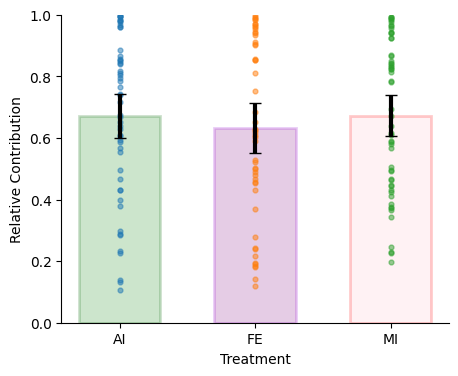

In [18]:
plt.figure(figsize=(5,4))
bars= plt.bar(
    summary["Treatment"],
    summary["mean"],
    yerr=summary["CI"],
    error_kw={
    "elinewidth":3,
    "capsize":4
    },
    alpha=0.2,
    width=0.6,
    color=["green","purple","pink"]
)
for bar, color in zip(
    bars,
    ["darkgreen","darkviolet","red"]
):
    bar.set_edgecolor(color)
    bar.set_linewidth(2)
for i,t in enumerate(summary["Treatment"]):
    values=(
        group_data[
            group_data["Treatment"]==t
        ]
        ["GroupRelativeContribution"]
    )
    plt.scatter(
    [i]*len(values),
    values,
    s=12,
    alpha=0.5
    )
plt.ylim(0,1)
plt.ylabel("Relative Contribution")
plt.xlabel("Treatment")
ax=plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.savefig(
    output_dir/"figure_4a.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Figure 4B — Group Relative Contribution Across Rounds


In [19]:
round_summary=data.groupby(["Treatment","Round"])[["GroupRelativeContribution"]].mean().reset_index()

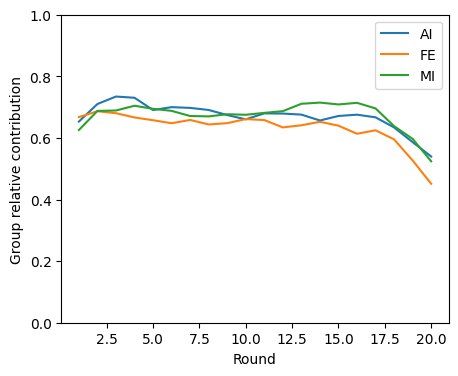

In [20]:
plt.figure(figsize=(5,4))
for group in round_summary["Treatment"].unique():
    temp=round_summary[round_summary["Treatment"]==group]
    plt.plot(
        temp["Round"],
        temp["GroupRelativeContribution"],
        label=group
    )
plt.ylim(0,1)
plt.xlabel("Round")
plt.ylabel("Group relative contribution")
plt.legend()
plt.savefig(
    output_dir/"figure_4b.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Figure 4C — Overall Surplus


In [21]:
summary_surplus=group_data.groupby("Treatment")["Surplus"].agg(["count","mean","std"])
summary_surplus = summary_surplus.reset_index()
summary_surplus["SE"]=summary_surplus["std"]/np.sqrt(summary_surplus["count"])
summary_surplus["CI"]=1.96*summary_surplus["SE"]

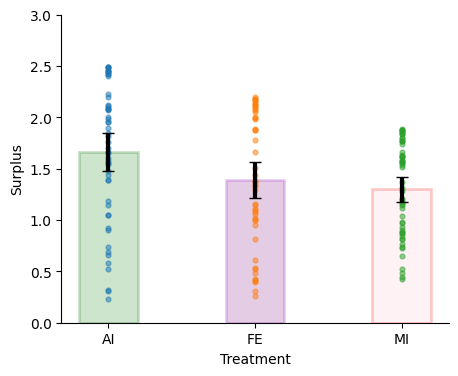

In [22]:
plt.figure(figsize=(5,4))
bars= plt.bar(
    summary_surplus["Treatment"],
    summary_surplus["mean"],
    yerr=summary_surplus["CI"],
    error_kw={
    "elinewidth":3,
    "capsize":4
    },
    alpha=0.2,
    width=0.4,
    color=["green","purple","pink"]
)
for bar, color in zip(
    bars,
    ["darkgreen","darkviolet","red"]
):
    bar.set_edgecolor(color)
    bar.set_linewidth(2)
for i,t in enumerate(summary_surplus["Treatment"]):
    values=(
        group_data[
            group_data["Treatment"]==t
        ]
        ["Surplus"]
    )
    plt.scatter(
    [i]*len(values),
    values,
    s=12,
    alpha=0.5
    )
plt.ylim(0,3)
plt.ylabel("Surplus")
plt.xlabel("Treatment")
ax=plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.savefig(
    output_dir/"figure_4c.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()